# Employee Data Analysis — Complete Exploratory Data Analysis (EDA)

## Introduction

Exploratory Data Analysis (EDA) is an essential step in the data science workflow. It involves examining, cleaning, analyzing, and visualizing data to understand its structure, identify patterns, and discover meaningful insights.

This project focuses on performing a complete Exploratory Data Analysis on an employee dataset using Python.

The analysis explores employee demographics, salary distributions, departments, geographical regions, employment status, performance scores, and remote-work patterns.

### Project Objectives

- Understand the structure and characteristics of the dataset.
- Identify missing values and data-quality issues.
- Clean and preprocess the dataset.
- Analyze numerical and categorical variables.
- Explore relationships between employee attributes.
- Perform descriptive and correlation analysis.
- Extract meaningful insights through data visualization.

### Tools and Libraries

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

In [212]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)

The original employee dataset is loaded using Pandas. It contains raw data that will be examined and prepared for further analysis.

In [213]:
df = pd.read_csv("Messy_Employee_dataset.csv", delimiter=',', parse_dates=['Join_Date'], date_format={'Join_Date' : '%m/%d/%Y'})
df.head()

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,DevOps-California,Active,2021-04-02,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,NaN,Finance-Texas,Active,2020-07-10,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,NaN,Admin-Nevada,Pending,2023-12-07,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,2021-11-27,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,2022-01-05,109324.61,frank.williams@example.com,-1586734256,Poor,False


Before conducting detailed analysis, an initial overview of the dataset is performed to understand its dimensions and examine its structure.

In [214]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Total Elements:", df.size)

df.info()

Number of Rows: 1020
Number of Columns: 12
Total Elements: 12240
<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Employee_ID        1020 non-null   str           
 1   First_Name         1020 non-null   str           
 2   Last_Name          1020 non-null   str           
 3   Age                809 non-null    float64       
 4   Department_Region  1020 non-null   str           
 5   Status             1020 non-null   str           
 6   Join_Date          1020 non-null   datetime64[us]
 7   Salary             996 non-null    float64       
 8   Email              1020 non-null   str           
 9   Phone              1020 non-null   int64         
 10  Performance_Score  1020 non-null   str           
 11  Remote_Work        1020 non-null   bool          
dtypes: bool(1), datetime64[us](1), float64(2), int64(1), str(7)
memo

## Data Understanding

Data understanding is an important stage of Exploratory Data Analysis. It involves examining the dataset's variables, data types, statistical properties, and unique values to understand the information available before performing data cleaning and further analysis.

In [215]:
df.describe(include='all')

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
count,1020,1020,1020,809.000000,1020,1020,1020,996.000000,1020,1.020000e+03,1020,1020
unique,1020,8,8,NaN,36,3,NaN,NaN,64,NaN,4,2
top,EMP1000,Frank,Brown,NaN,HR-Florida,Pending,NaN,NaN,grace.brown@example.com,NaN,Good,True
freq,1,142,148,NaN,41,356,NaN,NaN,27,NaN,270,513
mean,NaN,NaN,NaN,32.484549,NaN,NaN,2022-07-26 12:53:38.823529,85155.056396,NaN,-4.942253e+09,NaN,NaN
min,NaN,NaN,NaN,25.000000,NaN,NaN,2020-01-01 00:00:00,50047.320000,NaN,-9.994973e+09,NaN,NaN
25%,NaN,NaN,NaN,25.000000,NaN,NaN,2021-04-12 06:00:00,68392.487500,NaN,-7.341992e+09,NaN,NaN
50%,NaN,NaN,NaN,30.000000,NaN,NaN,2022-08-09 12:00:00,85547.870000,NaN,-4.943997e+09,NaN,NaN
75%,NaN,NaN,NaN,40.000000,NaN,NaN,2023-10-31 12:00:00,100974.027500,NaN,-2.520391e+09,NaN,NaN
max,NaN,NaN,NaN,40.000000,NaN,NaN,2024-12-29 00:00:00,119971.650000,NaN,-3.896086e+06,NaN,NaN


In [216]:
df.nunique()

Employee_ID          1020
First_Name              8
Last_Name               8
Age                     4
Department_Region      36
Status                  3
Join_Date             760
Salary                978
Email                  64
Phone                1020
Performance_Score       4
Remote_Work             2
dtype: int64

## Data Quality

Data quality analysis helps identify inconsistencies and potential problems in the dataset before cleaning and preprocessing. This stage focuses on missing values, duplicate records, and invalid or inconsistent data.

In [217]:
df.isnull().sum()

Employee_ID            0
First_Name             0
Last_Name              0
Age                  211
Department_Region      0
Status                 0
Join_Date              0
Salary                24
Email                  0
Phone                  0
Performance_Score      0
Remote_Work            0
dtype: int64

In [218]:
df.duplicated().sum()

np.int64(0)

In [219]:
df['Employee_ID'].duplicated().sum()

np.int64(0)

In [220]:
df.dtypes

Employee_ID                     str
First_Name                      str
Last_Name                       str
Age                         float64
Department_Region               str
Status                          str
Join_Date            datetime64[us]
Salary                      float64
Email                           str
Phone                         int64
Performance_Score               str
Remote_Work                    bool
dtype: object

## Data Cleaning

Data cleaning is the process of handling missing values, correcting inconsistencies, and transforming raw data into a suitable format for analysis.

In this stage, missing numerical values are handled, combined department and region information is separated into individual columns, and the cleaned dataset is prepared for further analysis.

In [221]:
cleaned_df = df.copy()

In [222]:
cleaned_df['Age'] = cleaned_df['Age'].fillna(cleaned_df['Age'].median())

cleaned_df['Salary'] = cleaned_df['Salary'].fillna(cleaned_df['Salary'].mean())

In [223]:
cleaned_df[['Department', 'Region']] = cleaned_df['Department_Region'].str.split('-', expand=True)

cleaned_df.drop(columns='Department_Region', inplace=True)

In [224]:
print("Missing Values:\n", cleaned_df.isnull().sum())
print("\nDataset Shape:", cleaned_df.shape)
cleaned_df.info()

Missing Values:
 Employee_ID          0
First_Name           0
Last_Name            0
Age                  0
Status               0
Join_Date            0
Salary               0
Email                0
Phone                0
Performance_Score    0
Remote_Work          0
Department           0
Region               0
dtype: int64

Dataset Shape: (1020, 13)
<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Employee_ID        1020 non-null   str           
 1   First_Name         1020 non-null   str           
 2   Last_Name          1020 non-null   str           
 3   Age                1020 non-null   float64       
 4   Status             1020 non-null   str           
 5   Join_Date          1020 non-null   datetime64[us]
 6   Salary             1020 non-null   float64       
 7   Email              1020 non-null   str          

In [225]:
cleaned_df.to_csv("Cleaned_Employee_Dataset.csv", index=False, date_format='%m/%d/%Y')

## Univariate Analysis

Univariate analysis examines individual variables independently to understand their distributions, central tendencies, and frequencies.

In this stage, numerical variables are analyzed using descriptive statistics, histograms, and boxplots, while categorical variables are examined through frequency distributions and count plots.

In [226]:
df = pd.read_csv("Cleaned_Employee_Dataset.csv", parse_dates=['Join_Date'], date_format={'Join_Date': '%m/%d/%Y'})

In [227]:
df[['Age', 'Salary']].describe()

,Age,Salary
count,1020.000000,1020.000000
mean,31.970588,85155.056396
std,5.136901,19638.295389
min,25.000000,50047.320000
25%,30.000000,68811.232500
50%,30.000000,85155.056396
75%,35.000000,100372.662500
max,40.000000,119971.650000


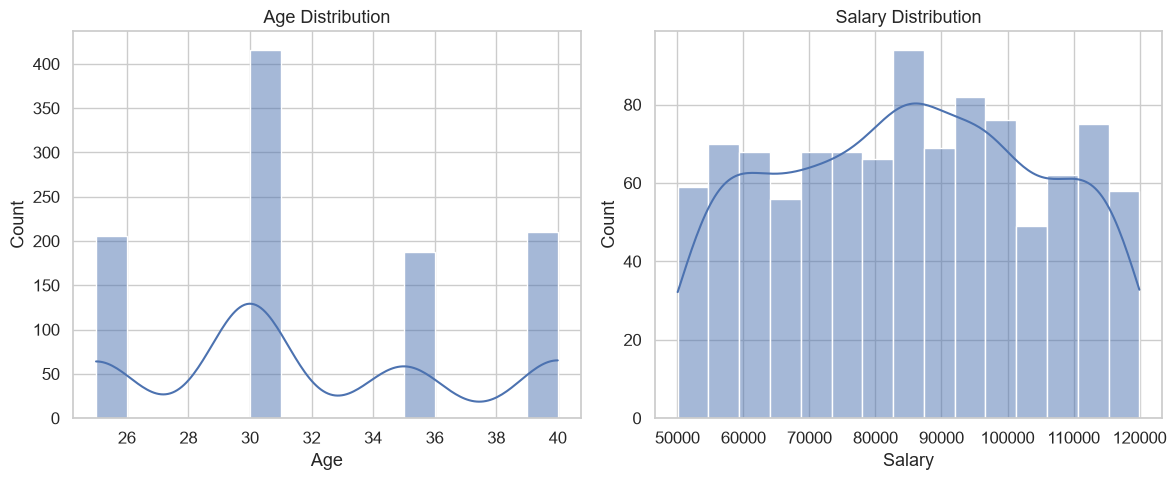

In [228]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df, x='Age', bins=15, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.histplot(data=df, x='Salary', bins=15, kde=True, ax=axes[1])
axes[1].set_title("Salary Distribution")

plt.tight_layout()
plt.show()

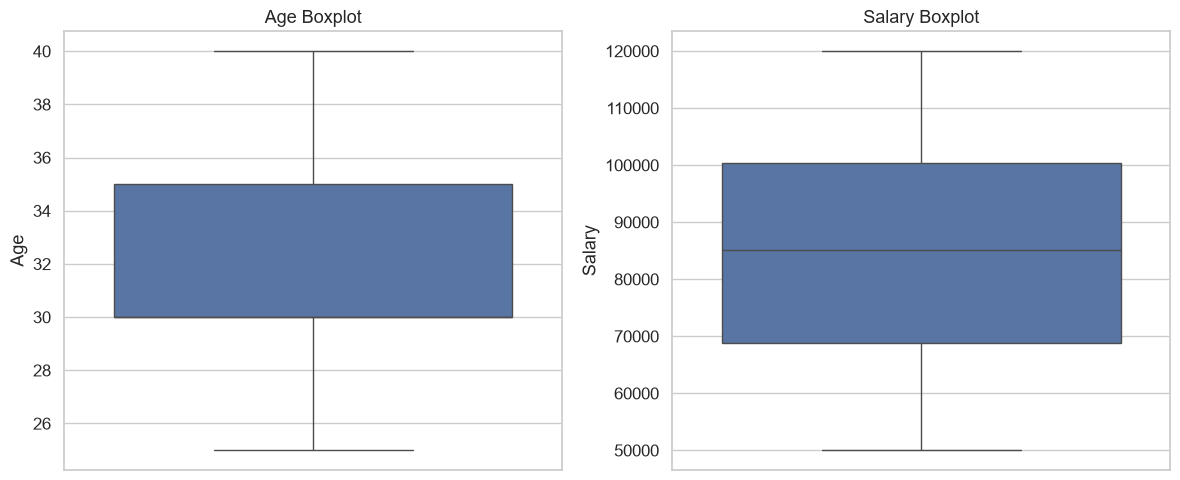

In [229]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, y='Age', ax=axes[0])
axes[0].set_title("Age Boxplot")

sns.boxplot(data=df, y='Salary', ax=axes[1])
axes[1].set_title("Salary Boxplot")

plt.tight_layout()
plt.show()

### Categorical Variables

Categorical analysis examines the frequency and distribution of non-numerical variables. It helps identify the most common categories and understand how employees are distributed across different groups.

In [230]:
categorical_columns = [
    'Department', 'Region', 'Status',
    'Performance_Score', 'Remote_Work'
]

for col in categorical_columns:
    print(f"\n{col}:\n")
    print(df[col].value_counts())
    print("\nPercentage:\n")
    print(df[col].value_counts(normalize=True) * 100)


Department:

Department
DevOps        189
Sales         178
HR            171
Finance       170
Admin         166
Cloud Tech    146
Name: count, dtype: int64

Percentage:

Department
DevOps        18.529412
Sales         17.450980
HR            16.764706
Finance       16.666667
Admin         16.274510
Cloud Tech    14.313725
Name: proportion, dtype: float64

Region:

Region
California    187
Florida       185
Nevada        169
Illinois      165
New York      161
Texas         153
Name: count, dtype: int64

Percentage:

Region
California    18.333333
Florida       18.137255
Nevada        16.568627
Illinois      16.176471
New York      15.784314
Texas         15.000000
Name: proportion, dtype: float64

Status:

Status
Pending     356
Active      352
Inactive    312
Name: count, dtype: int64

Percentage:

Status
Pending     34.901961
Active      34.509804
Inactive    30.588235
Name: proportion, dtype: float64

Performance_Score:

Performance_Score
Good         270
Average      267
Excell

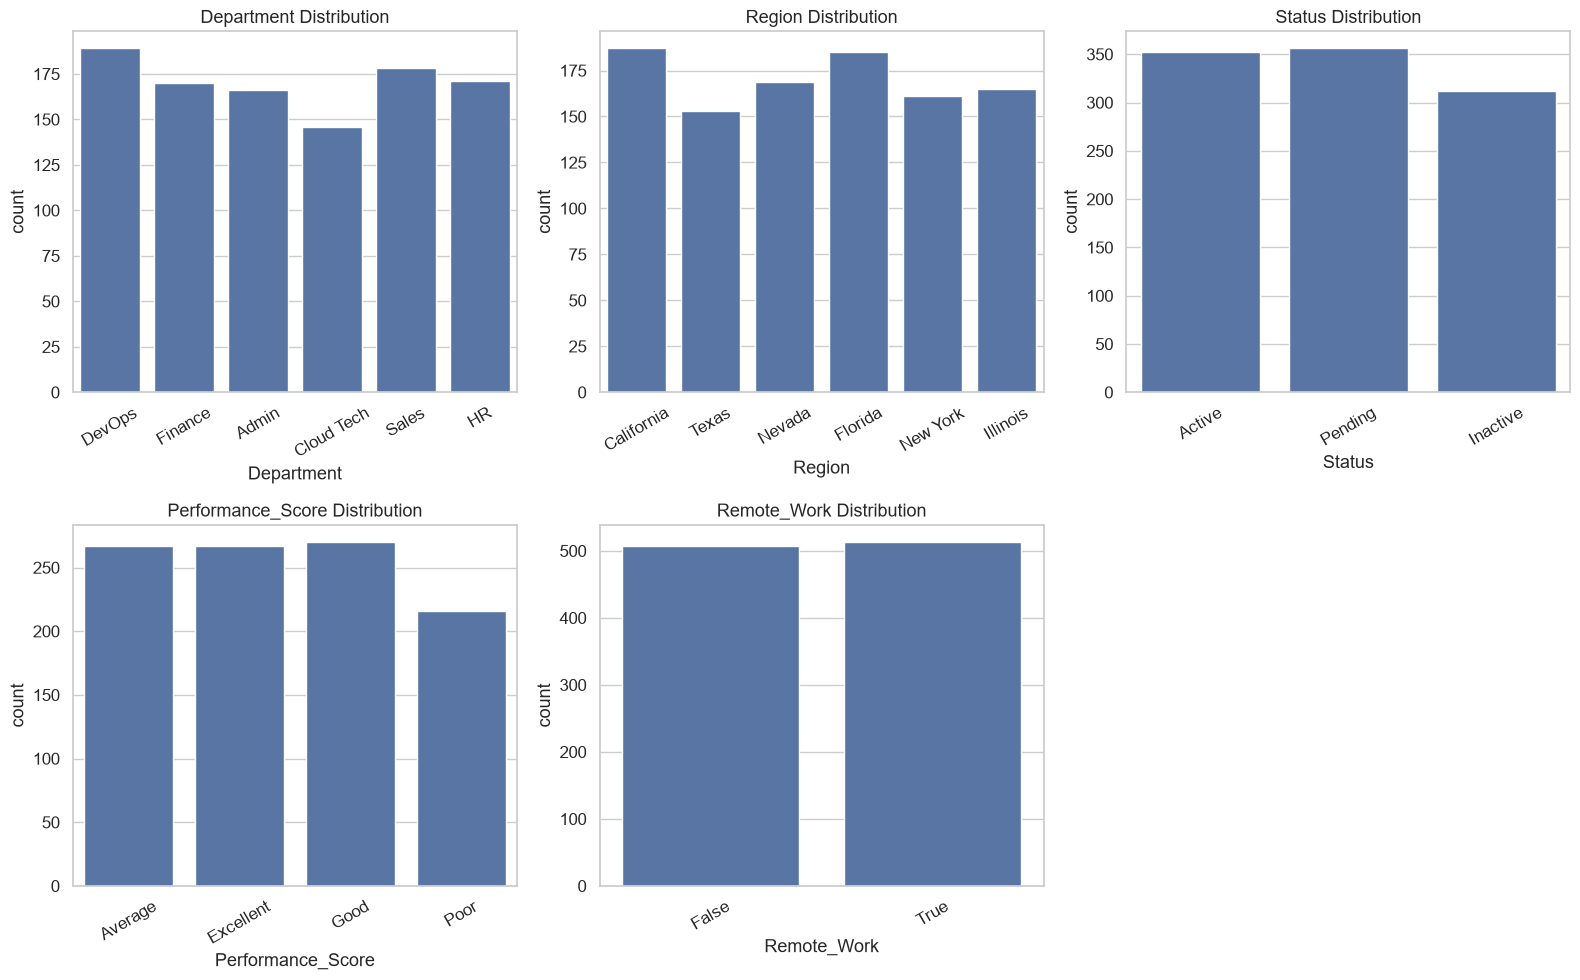

In [231]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(categorical_columns):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"{col} Distribution")
    axes[i].tick_params(axis='x', rotation=30)

axes[-1].axis('off')

plt.tight_layout()
plt.show()

## Bivariate Analysis

Bivariate analysis examines the relationship between two variables to identify associations, differences, and patterns within the dataset.

In this stage, numerical and categorical variables are compared using scatter plots, boxplots, and grouped visualizations to explore relationships between employee characteristics.

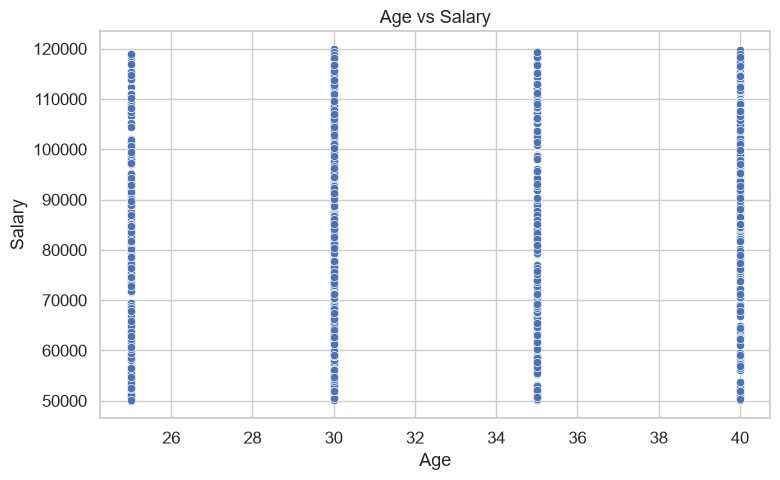

In [232]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Age', y='Salary')

plt.title("Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.tight_layout()
plt.show()

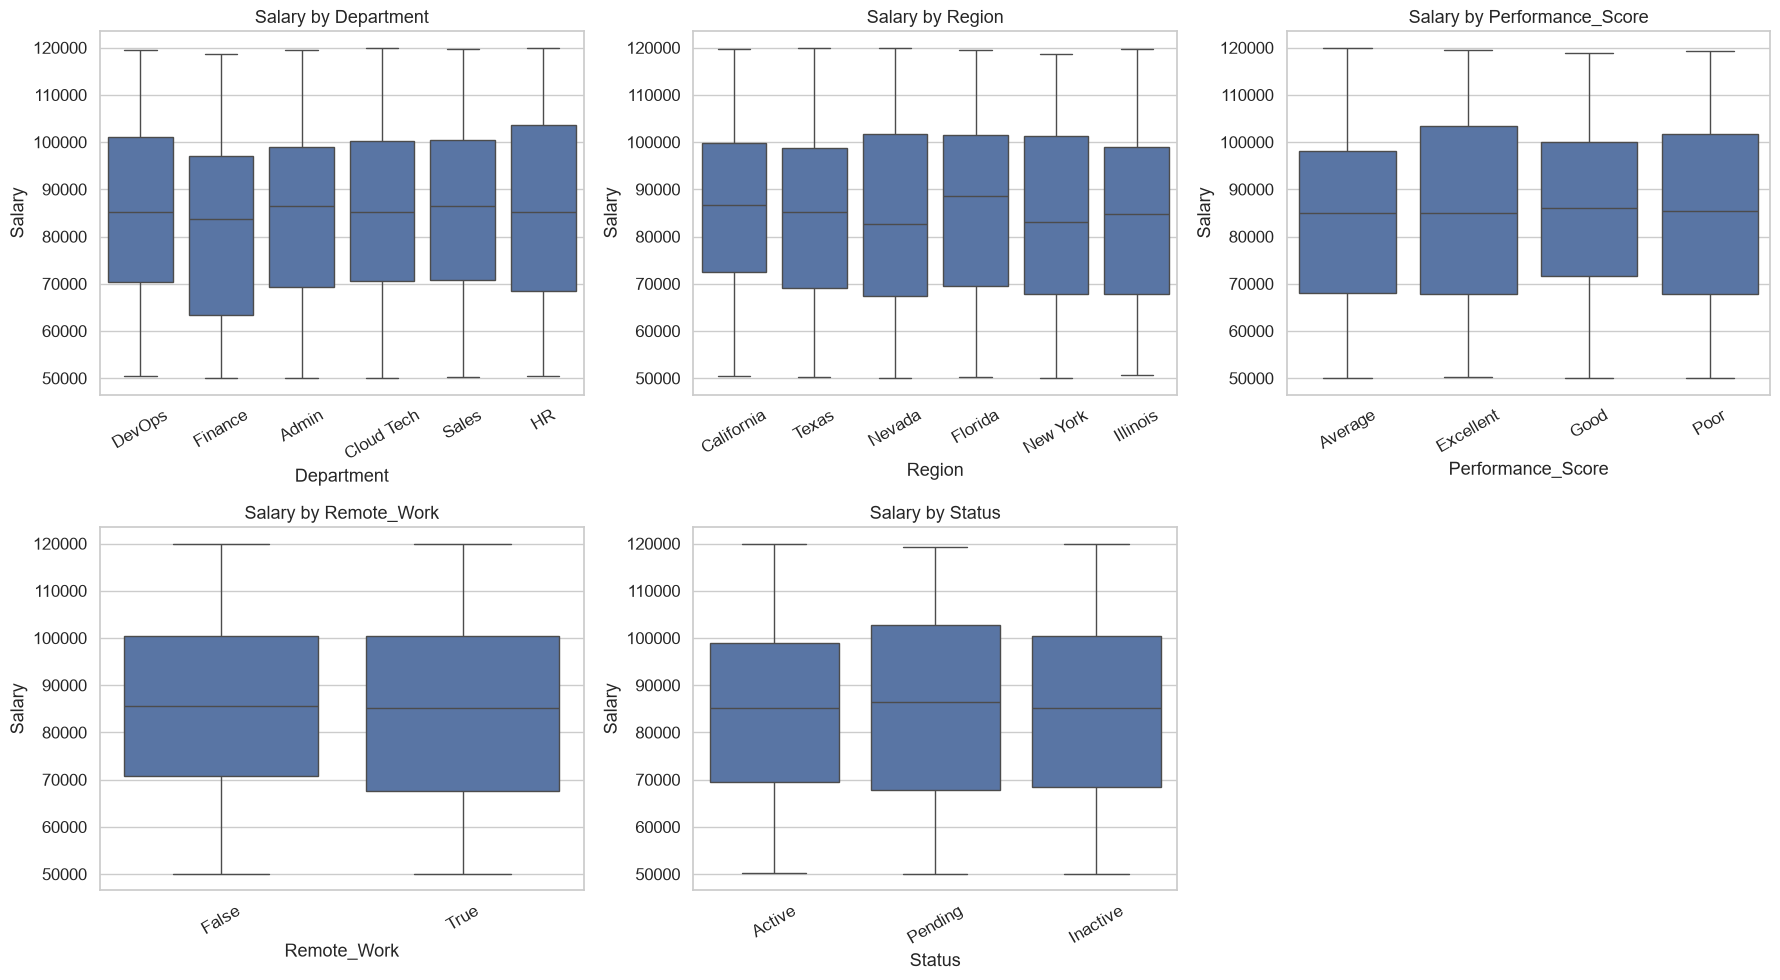

In [233]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

categorical_columns = [
    'Department', 'Region', 'Performance_Score',
    'Remote_Work', 'Status'
]

for i, col in enumerate(categorical_columns):
    sns.boxplot(data=df, x=col, y='Salary', ax=axes[i])
    axes[i].set_title(f"Salary by {col}")
    axes[i].tick_params(axis='x', rotation=30)

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [234]:
status_table = pd.crosstab(df['Department'], df['Status'])
status_table

Status,Active,Inactive,Pending
Department,,,
Admin,58,51,57
Cloud Tech,45,42,59
DevOps,78,58,53
Finance,49,62,59
HR,57,49,65
Sales,65,50,63


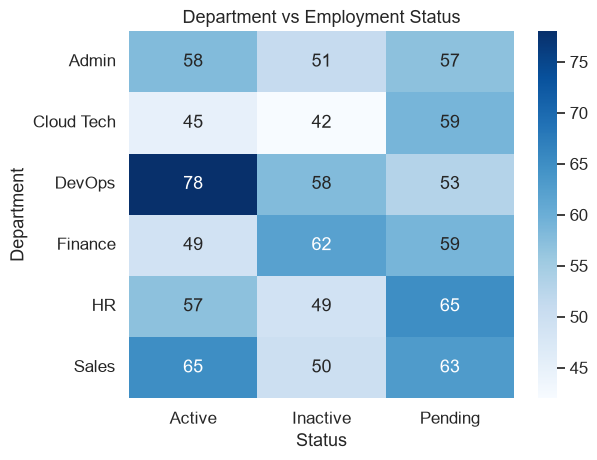

In [235]:
sns.heatmap(status_table, annot=True, fmt='d', cmap='Blues')

plt.title("Department vs Employment Status")
plt.tight_layout()
plt.show()

In [236]:
performance_table = pd.crosstab(df['Department'], df['Performance_Score'])
performance_table

Performance_Score,Average,Excellent,Good,Poor
Department,,,,
Admin,40,44,49,33
Cloud Tech,40,30,49,27
DevOps,49,47,50,43
Finance,48,45,35,42
HR,41,51,39,40
Sales,49,50,48,31


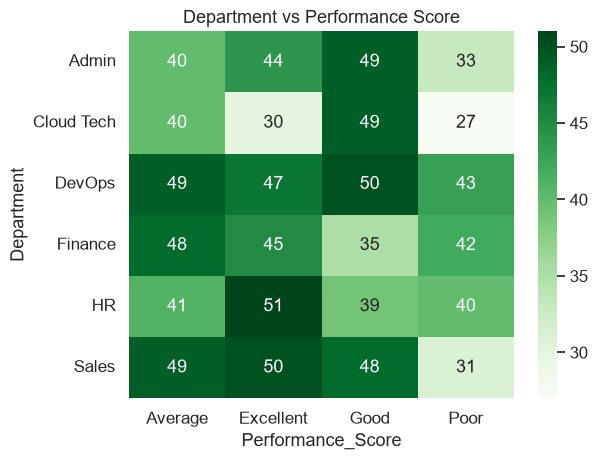

In [237]:
sns.heatmap(performance_table, annot=True, fmt='d', cmap='Greens')

plt.title("Department vs Performance Score")
plt.tight_layout()
plt.show()

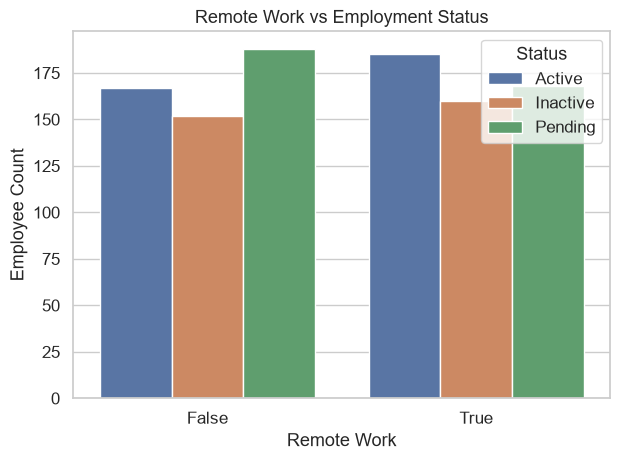

In [238]:
sns.countplot(data=df, x='Remote_Work', hue='Status')

plt.title("Remote Work vs Employment Status")
plt.xlabel("Remote Work")
plt.ylabel("Employee Count")

plt.tight_layout()
plt.show()

## Multivariate Analysis

Multivariate analysis examines relationships among three or more variables simultaneously. It helps identify complex patterns and understand how multiple employee characteristics interact.

In this stage, relationships between age, salary, department, performance scores, geographical regions, and employment status are explored using correlation heatmaps, grouped visualizations, and scatter plots.

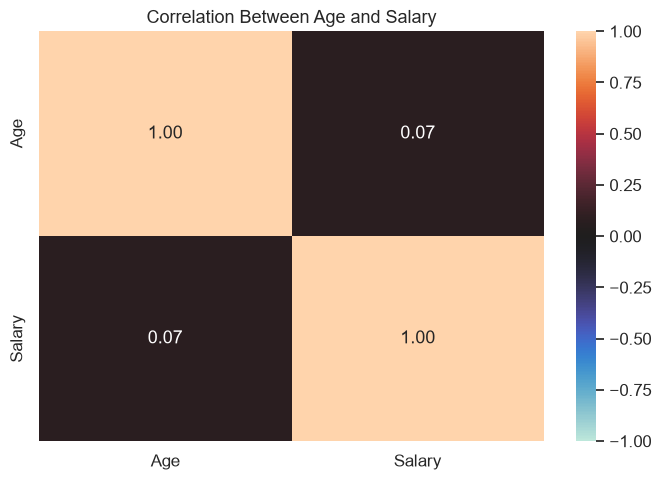

In [239]:
corr = df[['Age', 'Salary']].corr(method='spearman')

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between Age and Salary")
plt.tight_layout()
plt.show()

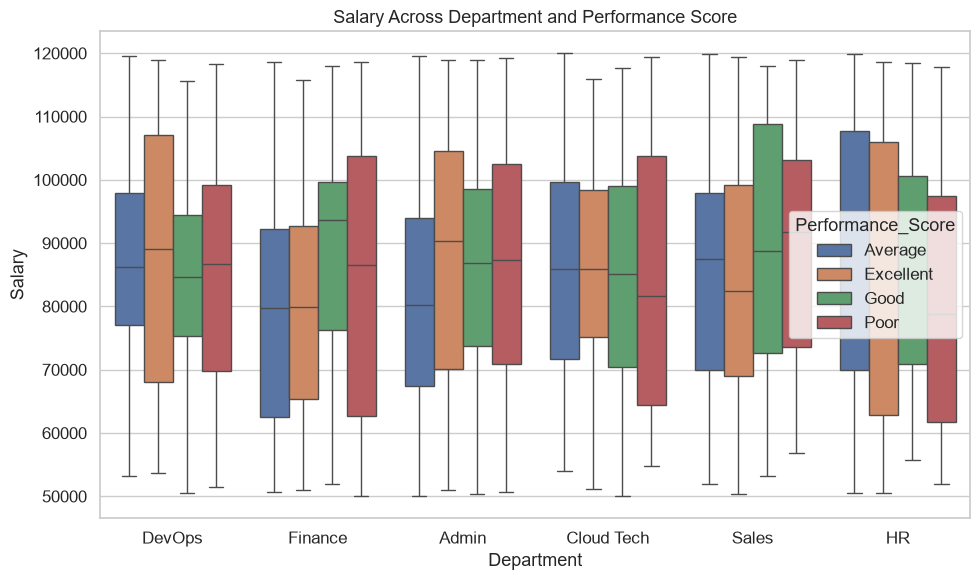

In [240]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Department',
    y='Salary',
    hue='Performance_Score'
)

plt.title("Salary Across Department and Performance Score")
plt.xlabel("Department")
plt.ylabel("Salary")

plt.tight_layout()
plt.show()

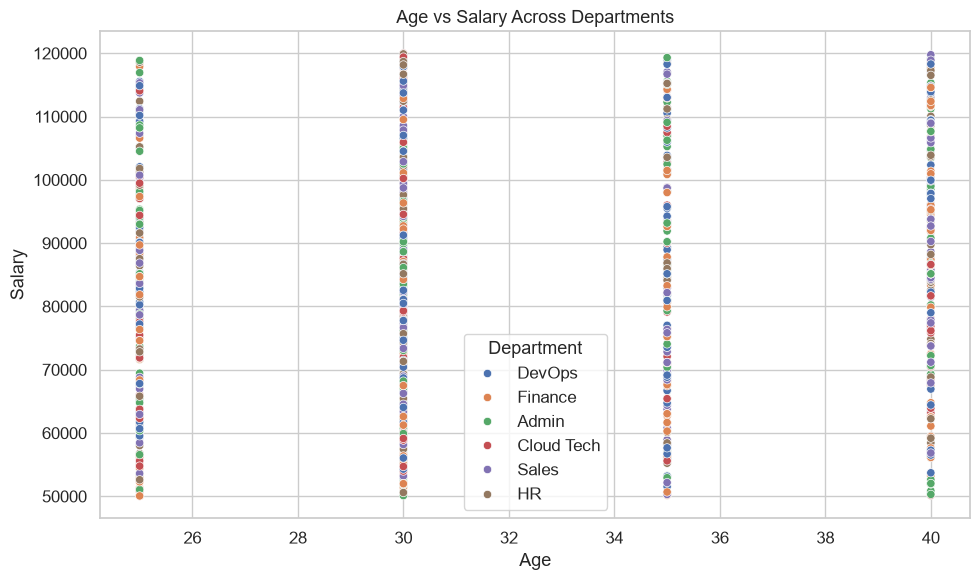

In [241]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Salary',
    hue='Department'
)

plt.title("Age vs Salary Across Departments")
plt.tight_layout()
plt.show()

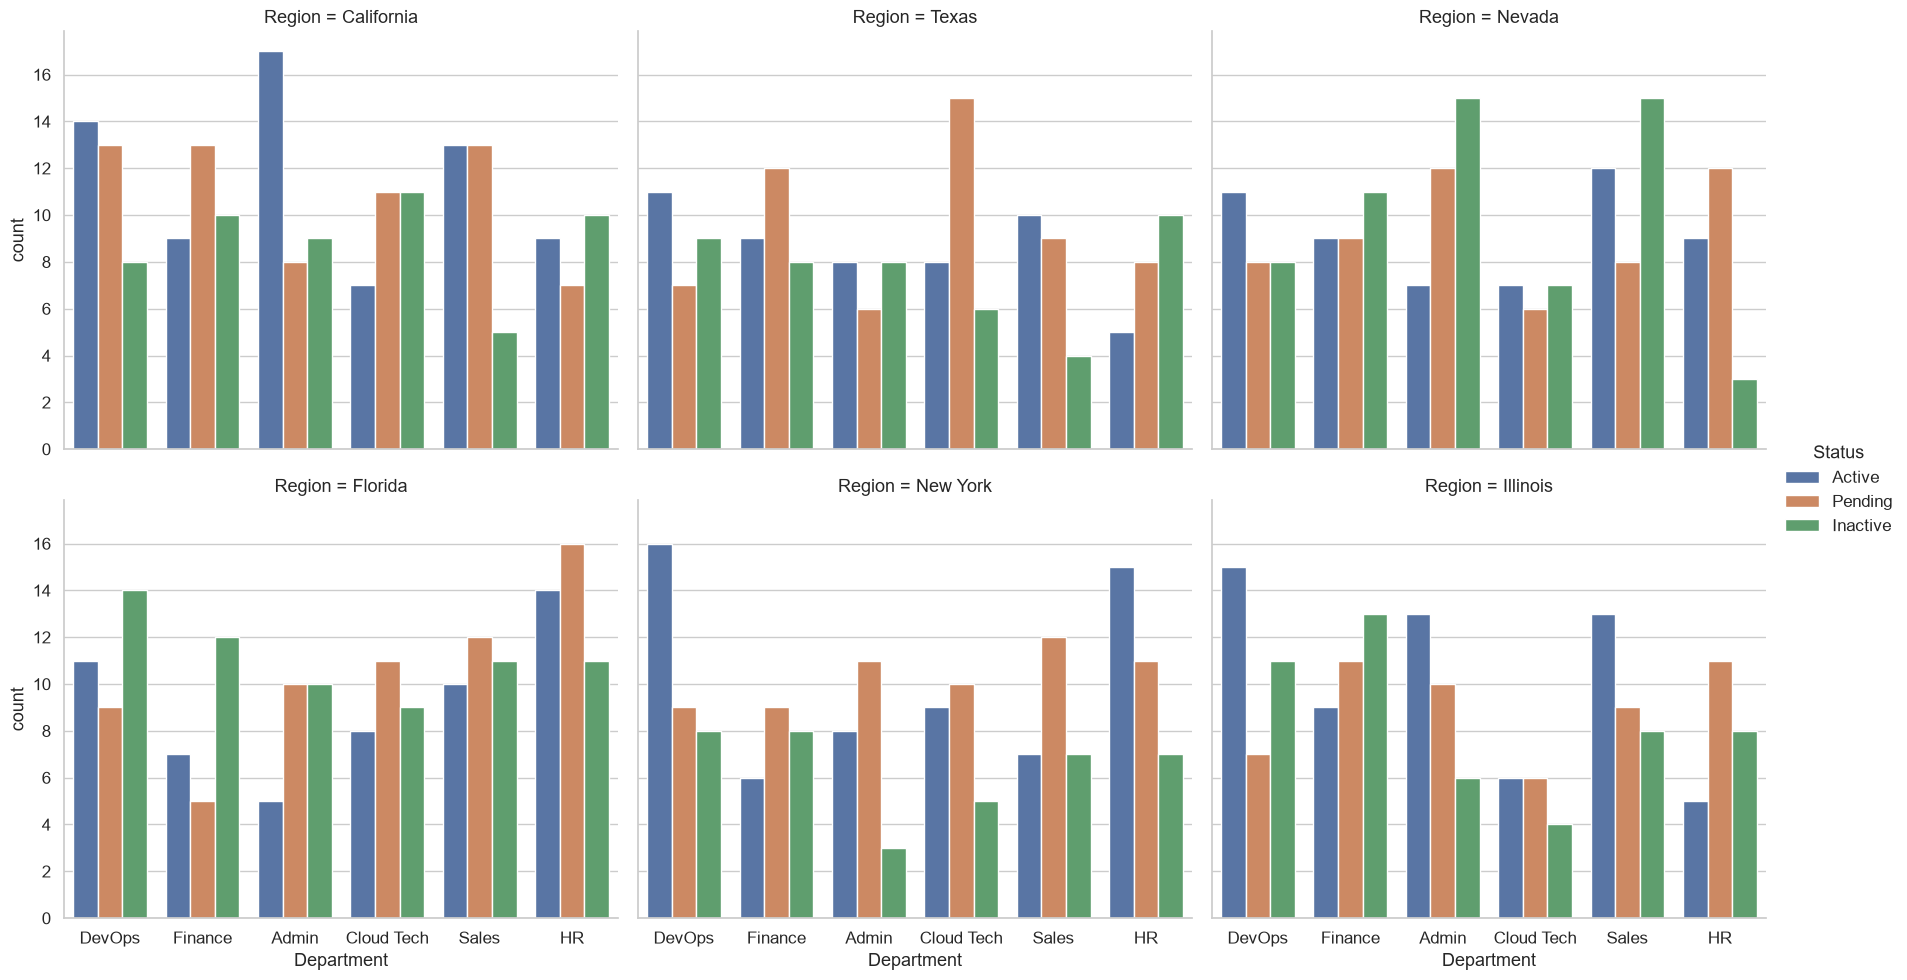

In [242]:
sns.catplot(
    data=df,
    x='Department',
    col='Region',
    hue='Status',
    kind='count',
    height=5,
    aspect=1.2,
    col_wrap=3
)

plt.show()

## Statistical Analysis

Statistical analysis uses descriptive measures and correlation coefficients to summarize numerical data and examine relationships between variables.

In this stage, descriptive statistics are calculated to understand the central tendency, variability, and distribution of employee age and salary. Pearson and Spearman correlation coefficients are also used to measure the strength and direction of their relationships.

In [243]:
numerical_data = df[['Age', 'Salary']]

print("Mean:\n", numerical_data.mean())
print("\nMedian:\n", numerical_data.median())
print("\nMode:\n", numerical_data.mode())
print("\nVariance:\n", numerical_data.var())
print("\nStandard Deviation:\n", numerical_data.std())
print("\nSkewness:\n", numerical_data.skew())
print("\nKurtosis:\n", numerical_data.kurtosis())

Mean:
 Age          31.970588
Salary    85155.056396
dtype: float64

Median:
 Age          30.000000
Salary    85155.056396
dtype: float64

Mode:
     Age        Salary
0  30.0  85155.056396

Variance:
 Age       2.638775e+01
Salary    3.856626e+08
dtype: float64

Standard Deviation:
 Age           5.136901
Salary    19638.295389
dtype: float64

Skewness:
 Age       0.297286
Salary   -0.019049
dtype: float64

Kurtosis:
 Age      -1.050566
Salary   -1.090269
dtype: float64


In [244]:
print("Pearson Correlation:")
print(numerical_data.corr(method='pearson'))

Pearson Correlation:
             Age    Salary
Age     1.000000  0.076693
Salary  0.076693  1.000000


In [245]:
print("Spearman Correlation:")
print(numerical_data.corr(method='spearman'))

Spearman Correlation:
             Age    Salary
Age     1.000000  0.072696
Salary  0.072696  1.000000


## Conclusion

### Summary

This project performed a complete Exploratory Data Analysis (EDA) on an employee dataset containing 1,020 records and 12 original columns. The analysis covered employee demographics, salaries, departments, geographical regions, employment status, performance scores, and remote-work patterns.

The workflow included data understanding, data-quality assessment, data cleaning, univariate analysis, bivariate analysis, multivariate analysis, and statistical analysis.

### Data Quality and Cleaning

- **Missing values:** Age contained 211 missing values (approximately 20.7%), while Salary contained 24 missing values (approximately 2.4%). Missing Age values were replaced with the median, and missing Salary values were replaced with the mean.
- **Duplicate records:** No duplicate rows or duplicate Employee_ID values were identified.
- **Data transformation:** The combined `Department_Region` column was separated into two individual columns: `Department` and `Region`.
- **Effect of imputation:** Replacing missing Age values with the median (30) increased the frequency of employees aged 30. This created an artificial concentration around that age and should be considered when interpreting the age distribution.

### Key Findings

**Employee Distributions**

- Salary values range approximately from 50,000 to 120,000, with a median close to 85,000. The distribution appears relatively symmetric, with no significant outliers identified through the boxplot.
- Age values are concentrated at four distinct values: 25, 30, 35, and 40. Median imputation further increased the frequency of age 30.
- Employment status, remote-work arrangements, departments, and geographical regions show relatively balanced distributions, although some categories have higher frequencies than others.
- DevOps is the largest department, with 189 employees, while Cloud Tech is the smallest, with 146 employees.

**Relationship Between Age and Salary**

- Spearman correlation indicates a very weak positive association between Age and Salary, with a coefficient of approximately 0.07.
- The scatter plot also shows no clear relationship between increasing age and salary.
- This suggests that age has little observable association with salary in this dataset.

**Salary Across Employee Groups**

- Salary distributions appear broadly similar across departments, geographical regions, performance scores, remote-work arrangements, and employment statuses.
- No substantial differences in salary distributions are visually apparent between these groups.
- Higher performance scores do not show a clear pattern of higher salaries in the analyzed data.

**Relationships Between Categorical Variables**

- Department, employment status, performance score, and remote-work arrangements show no obvious strong patterns of association in the visualizations.
- Some individual department-region-status combinations have higher or lower employee counts, but these differences should be interpreted carefully because individual groups contain relatively small numbers of employees.

### Interpretation

The dataset displays relatively simple distributions and limited visible relationships between employee attributes. In a real-world workforce dataset, salary may be associated with factors such as experience, seniority, and performance. However, these relationships are not clearly visible in the current dataset.

The balanced category distributions, restricted age values, and weak observable relationships suggest that the dataset may be synthetic or simplified. Therefore, it is useful for practicing data cleaning, exploratory analysis, and visualization, but its findings should not be treated as representative of real-world workforce behavior.

### Limitations

- **Age imputation:** Approximately 20.7% of Age values were missing. Median imputation introduced additional observations at age 30, potentially affecting age-related findings.
- **Salary imputation:** Mean imputation was used because the salary distribution appeared relatively symmetric. However, imputed values may still affect descriptive statistics and group comparisons.
- **Limited variables:** The dataset does not provide enough information about factors such as education, experience, seniority, or job level to explain salary differences.
- **Association versus causation:** Observed relationships and patterns do not establish causal relationships between employee attributes.
- **Generalizability:** The findings apply only to this dataset and should not be generalized to actual employee populations.